| Seção | Conteúdo |
|---|---|
| 1 | Configuração |
| 2 | Leitura, limpeza e junção dos dados (3.2)|
| 3 | Análise exploratória (3.3) |
| 4 | Definição de evento extremo (3.6) |
| 5 | Estimativa da defasagem (3.4) |
| 6 | Chuva acumulada e análise de limiar (3.5) |
| 7 | Modelo de probabilidade de vazão extrema (3.7) |
| 8 | Verificação de robustez (3.8) |

## 1. Configuração

In [ ]:
import io
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, precision_recall_curve,
                             precision_recall_fscore_support, roc_auc_score, roc_curve)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams["figure.dpi"] = 100

_UPLOADS = Path("/mnt/user-data/uploads")
DATA_DIR = _UPLOADS if _UPLOADS.exists() else Path(".")
OUT = Path("/mnt/user-data/outputs/resultados") if _UPLOADS.exists() else Path("resultados")
OUT.mkdir(parents=True, exist_ok=True)

ANA_FILE = DATA_DIR / "ana_chuva_sabara_1943006.csv"
INMET_FILE = DATA_DIR / "inmet_meteo_bh_83587.csv"
GLOFAS_FILE = DATA_DIR / "glofas_vazao_sabara.csv"

MAX_LAG = 10                    # defasagem máxima testada (dias)
JANELAS = [1, 3, 7, 15, 30]     # janelas de chuva acumulada (dias)
PCT_PRINCIPAL = 0.95            # limiar principal de evento extremo
PCT_RESTRITIVO = 0.99
GAP_EVENTO = 7                  # dias entre excedências para formar um mesmo evento
LOOKBACK = 10                   # dias antes do pico para procurar a maior chuva
MIN_CHUVA_EVENTO = 20           # mm; eventos com chuva máxima abaixo disso são marcados como "sem chuva relevante"
ANO_CORTE = 2015                # treino: <= ANO_CORTE | teste: > ANO_CORTE
MESES_CHUVOSOS = [11, 12, 1, 2, 3]
N_BOOT = 1000                   # reamostragens do bootstrap
BLOCO = 30                      # tamanho do bloco (dias) no bootstrap
SEED = 42

#ajuste do rótulo do dia das séries de chuva
#0 = como registrado | -1 = atribuir a chuva ao dia anterior
AJUSTE_ANA = 0
AJUSTE_INMET = 0

print("Dados em:", DATA_DIR.resolve())
print("Resultados em:", OUT.resolve())

Dados em: /mnt/user-data/uploads
Resultados em: /mnt/user-data/outputs/resultados


In [2]:
def salvar_fig(nome):
    """Salva a figura em OUT e a exibe no notebook."""
    plt.tight_layout()
    plt.savefig(OUT / nome, dpi=150)
    plt.show()


def chuva_acumulada(chuva, n):
    """Total móvel dos últimos n dias, incluindo o dia t. Janelas com falta de dado viram NaN."""
    return chuva.rolling(n, min_periods=n).sum()


def correlacao_defasada(serie_resp, chuva, lags, mascara=None):
    """Spearman entre serie_resp(t) e chuva(t-k), para cada k. 'mascara' restringe os dias t usados."""
    out = {}
    for k in lags:
        d = pd.concat([serie_resp, chuva.shift(k)], axis=1).dropna()
        if mascara is not None:
            d = d[mascara.loc[d.index]]
        out[k] = d.iloc[:, 0].corr(d.iloc[:, 1], method="spearman")
    return pd.Series(out)


def correlacao_janelas(df, chuva_col="rain_mm", mascara=None):
    """Spearman entre a vazão e a chuva acumulada em cada janela."""
    out = {}
    for n in JANELAS:
        d = pd.concat([df["flow_m3s"], chuva_acumulada(df[chuva_col], n)], axis=1).dropna()
        if mascara is not None:
            d = d[mascara.loc[d.index]]
        out[n] = d.iloc[:, 0].corr(d.iloc[:, 1], method="spearman")
    return pd.Series(out)


def melhor_defasagem(df, col, mascara):
    return int(correlacao_defasada(df["flow_m3s"], df[col], range(MAX_LAG + 1), mascara).idxmax())


def melhor_janela(df, col, mascara):
    return int(correlacao_janelas(df, col, mascara).idxmax())

## 2. Leitura, limpeza e junção dos dados (seção 3.2)

In [3]:
def ler_texto(path, encodings):
    """Lê o arquivo tentando cada codificação até uma funcionar."""
    for enc in encodings:
        try:
            return Path(path).read_text(encoding=enc)
        except UnicodeDecodeError:
            continue
    raise UnicodeDecodeError("desconhecida", b"", 0, 1, f"não foi possível decodificar {path}")


def texto_a_partir_do_cabecalho(path, inicio, encodings):
    """Descarta as linhas de metadados que antecedem o cabeçalho real."""
    linhas = ler_texto(path, encodings).splitlines()
    i = next(i for i, linha in enumerate(linhas) if linha.startswith(inicio))
    return "\n".join(linhas[i:])


def converter_datas(serie):
    """Aceita datas DD/MM/AAAA ou AAAA-MM-DD e falha de forma explícita se nenhum formato servir."""
    for formato in ("%d/%m/%Y", "%Y-%m-%d"):
        datas = pd.to_datetime(serie, format=formato, errors="coerce")
        if datas.notna().mean() > 0.99:
            return datas
    raise ValueError("Formato de data não reconhecido. Exemplo: " + str(serie.iloc[0]))


def load_glofas(path=GLOFAS_FILE):
    df = pd.read_csv(path, encoding="utf-8-sig")
    df = df.rename(columns={"data": "date", "vazao_m3s": "flow_m3s"})
    df["date"] = converter_datas(df["date"].astype(str))
    return df.set_index("date").sort_index()[["flow_m3s"]]


def load_inmet(path=INMET_FILE):
    texto = texto_a_partir_do_cabecalho(path, "Data Medicao", ("utf-8-sig", "latin-1"))
    df = pd.read_csv(io.StringIO(texto), sep=";", na_values=["null", ""], index_col=False)
    df.columns = [c.split(",")[0].strip() for c in df.columns]      # nomes curtos
    col_chuva = next(c for c in df.columns if c.upper().startswith("PRECIP"))
    df = df.rename(columns={"Data Medicao": "date", col_chuva: "rain_inmet_mm"})
    df["date"] = converter_datas(df["date"].astype(str))
    return df.set_index("date").sort_index()[["rain_inmet_mm"]]


def load_ana(path=ANA_FILE):
    texto = texto_a_partir_do_cabecalho(path, "EstacaoCodigo", ("latin-1",))
    df = pd.read_csv(io.StringIO(texto), sep=";", decimal=",", index_col=False)
    df["Data"] = converter_datas(df["Data"].astype(str))

    # meses duplicados: 1 = bruto, 2 = consistido -> mantém o consistido
    df = (df.sort_values(["Data", "NivelConsistencia"], ascending=[True, False])
            .drop_duplicates("Data", keep="first"))

    # formato largo (uma linha por mês) -> longo (uma linha por dia)
    colunas_dia = [f"Chuva{d:02d}" for d in range(1, 32)]
    longo = df.melt(id_vars=["Data"], value_vars=colunas_dia, var_name="dia", value_name="rain_mm")
    longo["dia"] = longo["dia"].str[-2:].astype(int)

    # data real; datas inexistentes (ex.: 30 de fevereiro) viram NaT e são descartadas
    longo["date"] = pd.to_datetime(
        dict(year=longo["Data"].dt.year, month=longo["Data"].dt.month, day=longo["dia"]),
        errors="coerce")
    longo = longo.dropna(subset=["date"])
    return longo.set_index("date")[["rain_mm"]].sort_index()


ana = load_ana()          # chuva principal (coluna rain_mm)
inmet = load_inmet()      # chuva de verificação (coluna rain_inmet_mm)
glofas = load_glofas()    # vazão (coluna flow_m3s)

for nome, d in [("ANA", ana), ("INMET", inmet), ("GloFAS", glofas)]:
    print(f"{nome:7s} {d.index.min().date()} -> {d.index.max().date()} | linhas: {len(d):6d} | "
          f"datas duplicadas: {d.index.duplicated().sum()} | ausentes: {int(d.iloc[:, 0].isna().sum())}")

ANA     1941-06-01 -> 2026-04-30 | linhas:  31015 | datas duplicadas: 0 | ausentes: 2041
INMET   1986-01-01 -> 2026-04-30 | linhas:  14730 | datas duplicadas: 0 | ausentes: 10
GloFAS  1997-01-01 -> 2026-04-30 | linhas:  10712 | datas duplicadas: 0 | ausentes: 0


### Junção das séries

In [ ]:
df = glofas.join(ana, how="left").join(inmet, how="left").sort_index()

df["rain_mm"] = df["rain_mm"].shift(AJUSTE_ANA)
df["rain_inmet_mm"] = df["rain_inmet_mm"].shift(AJUSTE_INMET)

dias_esperados = (df.index.max() - df.index.min()).days + 1
print("Período:", df.index.min().date(), "->", df.index.max().date())
print("Dias:", len(df), "| lacunas no calendário:", dias_esperados - len(df))
print("Datas duplicadas:", df.index.duplicated().sum())
print("Valores ausentes por coluna:")
print(df.isna().sum().to_string())

# máscara do período de treino e limiares de vazão calculados somente com o treino
treino = pd.Series(df.index.year <= ANO_CORTE, index=df.index)
LIM95 = df.loc[treino, "flow_m3s"].quantile(PCT_PRINCIPAL)
LIM99 = df.loc[treino, "flow_m3s"].quantile(PCT_RESTRITIVO)
print(f"\nTreino: {int(treino.sum())} dias (até {ANO_CORTE}) | teste: {int((~treino).sum())} dias")
print(f"Limiares (calculados no treino): P95 = {LIM95:.2f} m³/s | P99 = {LIM99:.2f} m³/s")
print(f"Limiares na série completa, só para comparação: P95 = {df['flow_m3s'].quantile(.95):.2f} | "
      f"P99 = {df['flow_m3s'].quantile(.99):.2f}")
df.head()

Período: 1997-01-01 -> 2026-04-30
Dias: 10712 | lacunas no calendário: 0
Datas duplicadas: 0
Valores ausentes por coluna:
flow_m3s         0
rain_mm          7
rain_inmet_mm    3

Treino: 6939 dias (até 2015) | teste: 3773 dias
Limiares (calculados no treino): P95 = 9.69 m³/s | P99 = 18.88 m³/s
Limiares na série completa, só para comparação: P95 = 9.30 | P99 = 19.08


,flow_m3s,rain_mm,rain_inmet_mm
date,,,
1997-01-01,11.25,0.0,16.3
1997-01-02,12.52,20.9,13.5
1997-01-03,17.97,58.1,109.2
1997-01-04,28.85,20.4,147.4
1997-01-05,33.67,10.2,48.6


### 2.1 Alinhamento temporal das fontes

| Fonte | Janela diária | Observação |
|---|---|---|
| ANA | leitura às 7h (local, ≈ 10 UTC) | totaliza a chuva das 7h do dia anterior às 7h do dia |
| INMET (estação convencional) | leitura às 12 UTC (≈ 9h local) | totaliza as 24 h anteriores |
| GloFAS | dia em UTC (00h-24h UTC ≈ 21h do dia anterior às 21h local) | vazão diária da reanálise |

Como as duas estações fecham o dia de manhã, uma chuva de fim de tarde ou noite recebe o rótulo do dia seguinte, enquanto a vazão do GloFAS já está no dia UTC da chuva. Isso pode mudar a defasagem em até 1 dia. 
Mede (a) como as duas estações se alinham entre si e (b) quanto muda a defasagem se a chuva for atribuída ao dia anterior. O resultado entra no artigo como faixa (por exemplo, "1 a 2 dias").

In [5]:
def passo_horario(df):
    # (a) alinhamento relativo entre as duas estações: ANA(t) vs INMET(t+s)
    linhas = []
    for s in range(-2, 3):
        linhas.append({"deslocamento_INMET_dias": s,
                       "Spearman_ANA_vs_INMET": df["rain_mm"].corr(df["rain_inmet_mm"].shift(-s),
                                                                    method="spearman")})
    tab_est = pd.DataFrame(linhas).round(3)
    print("(a) Correlação diária entre as estações segundo o deslocamento do INMET:")
    display(tab_est)

    # (b) sensibilidade da defasagem (período de treino)
    linhas = []
    for nome, col in [("ANA", "rain_mm"), ("INMET", "rain_inmet_mm")]:
        for ajuste, descr in [(0, "rótulo original"), (-1, "chuva atribuída ao dia anterior")]:
            tab = correlacao_defasada(df["flow_m3s"], df[col].shift(ajuste), range(MAX_LAG + 1), treino)
            linhas.append({"serie": nome, "alinhamento": descr,
                           "melhor_defasagem_dias": int(tab.idxmax()), "spearman_max": round(tab.max(), 3)})
    tab_sens = pd.DataFrame(linhas)
    tab_sens.to_csv(OUT / "2_1_sensibilidade_horario.csv", index=False)
    print("(b) Defasagem ótima (treino) conforme o rótulo do dia da chuva:")
    display(tab_sens)


passo_horario(df)

(a) Correlação diária entre as estações segundo o deslocamento do INMET:


,deslocamento_INMET_dias,Spearman_ANA_vs_INMET
0,-2,0.392
1,-1,0.552
2,0,0.792
3,1,0.497
4,2,0.375


(b) Defasagem ótima (treino) conforme o rótulo do dia da chuva:


,serie,alinhamento,melhor_defasagem_dias,spearman_max
0,ANA,rótulo original,1,0.499
1,ANA,chuva atribuída ao dia anterior,2,0.499
2,INMET,rótulo original,1,0.486
3,INMET,chuva atribuída ao dia anterior,2,0.486


## 3. Análise exploratória (seção 3.3)

,variavel,n,media,mediana,desvio_padrao,maximo,p90,p95,p99
0,Chuva ANA (mm),10705,4.04,0.00,11.48,158.20,13.80,26.8,56.18
1,Vazão GloFAS (m³/s),10712,2.38,1.08,3.66,48.55,6.01,9.3,19.08


Proporção de dias com chuva >= 1 mm: 24.0%


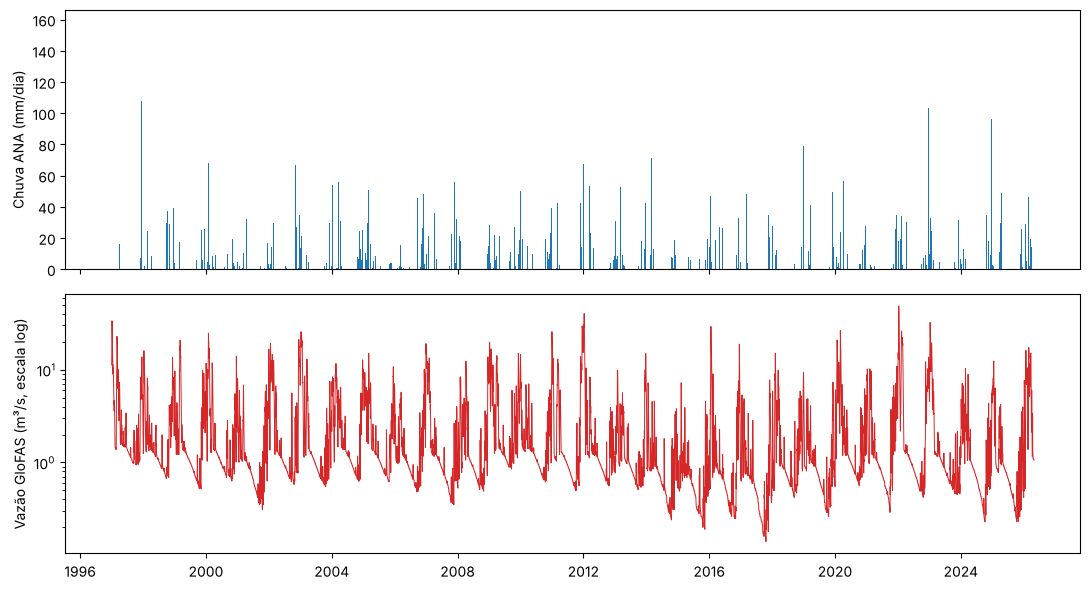

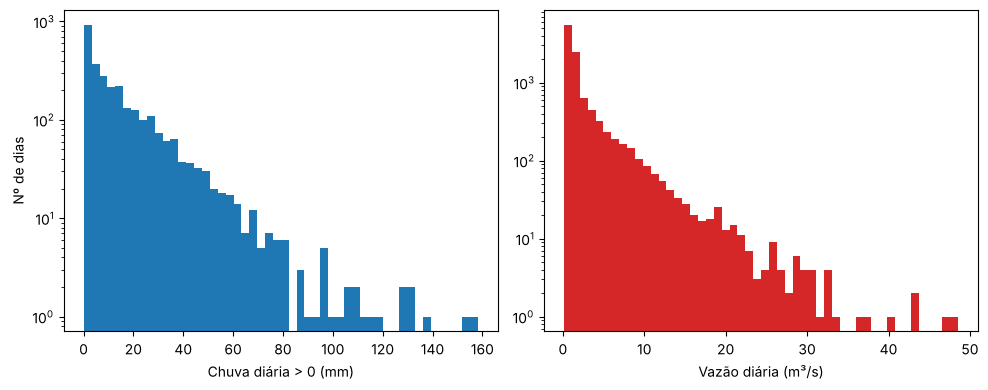

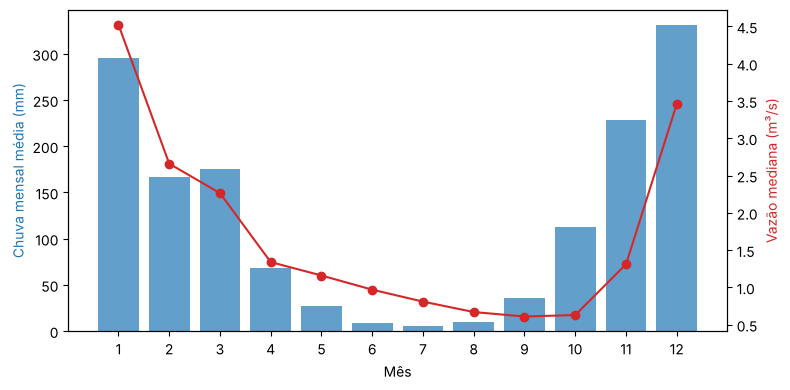

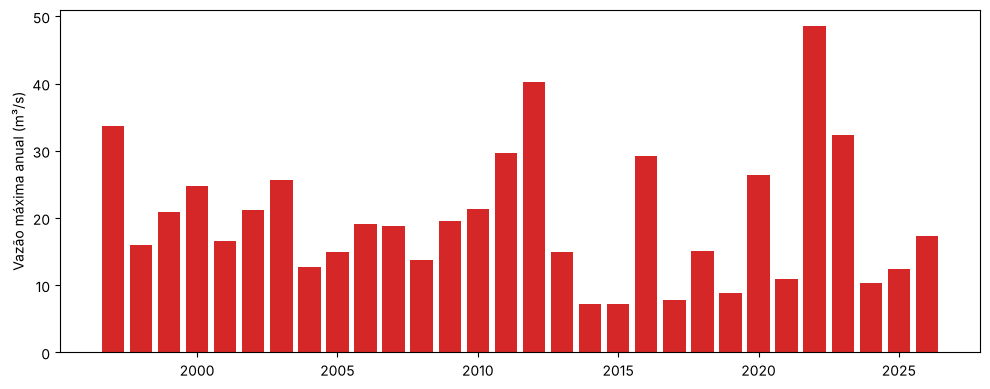

Maiores chuvas diárias (ANA):
date
2003-01-16    158.2
2020-01-25    152.8
2007-10-19    137.7
2021-02-08    132.6
2024-01-14    131.4
Maiores vazões diárias (GloFAS):
date
2022-01-10    48.6
2022-01-11    46.9
2022-01-09    43.6
2022-01-12    42.8
2012-01-10    40.3


In [6]:
def passo_exploracao(df):
    nomes = {"rain_mm": "Chuva ANA (mm)", "flow_m3s": "Vazão GloFAS (m³/s)"}
    linhas = []
    for c, nome in nomes.items():
        s = df[c].dropna()
        linhas.append({"variavel": nome, "n": len(s), "media": s.mean(), "mediana": s.median(),
                       "desvio_padrao": s.std(), "maximo": s.max(),
                       "p90": s.quantile(0.90), "p95": s.quantile(0.95), "p99": s.quantile(0.99)})
    tab = pd.DataFrame(linhas).round(2)
    tab.to_csv(OUT / "3_3_estatisticas_descritivas.csv", index=False)
    display(tab)

    chuva = df["rain_mm"].dropna()
    print(f"Proporção de dias com chuva >= 1 mm: {(chuva >= 1).mean():.1%}")

    # Série temporal
    fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
    ax[0].bar(df.index, df["rain_mm"], width=1, color="tab:blue")
    ax[0].set_ylabel("Chuva ANA (mm/dia)")
    ax[1].plot(df.index, df["flow_m3s"], color="tab:red", lw=0.7)
    ax[1].set_yscale("log")
    ax[1].set_ylabel("Vazão GloFAS (m³/s, escala log)")
    salvar_fig("3_3_serie_temporal.png")

    # Histogramas
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].hist(chuva[chuva > 0], bins=50, color="tab:blue")
    ax[0].set_yscale("log")
    ax[0].set_xlabel("Chuva diária > 0 (mm)")
    ax[0].set_ylabel("Nº de dias")
    ax[1].hist(df["flow_m3s"], bins=50, color="tab:red")
    ax[1].set_yscale("log")
    ax[1].set_xlabel("Vazão diária (m³/s)")
    salvar_fig("3_3_histogramas.png")

    # Ciclo sazonal: total mensal médio de chuva e vazão mediana por mês
    total_mensal = df["rain_mm"].groupby([df.index.year, df.index.month]).sum(min_count=25)
    chuva_mes = total_mensal.groupby(level=1).mean()
    vazao_mes = df["flow_m3s"].groupby(df.index.month).median()
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(chuva_mes.index, chuva_mes.values, color="tab:blue", alpha=0.7)
    ax.set_xlabel("Mês")
    ax.set_ylabel("Chuva mensal média (mm)", color="tab:blue")
    ax2 = ax.twinx()
    ax2.plot(vazao_mes.index, vazao_mes.values, color="tab:red", marker="o")
    ax2.set_ylabel("Vazão mediana (m³/s)", color="tab:red")
    ax.set_xticks(range(1, 13))
    salvar_fig("3_3_ciclo_sazonal.png")

    # Vazão máxima anual
    maxima = df["flow_m3s"].groupby(df.index.year).max()
    plt.figure(figsize=(10, 4))
    plt.bar(maxima.index, maxima.values, color="tab:red")
    plt.ylabel("Vazão máxima anual (m³/s)")
    salvar_fig("3_3_vazao_maxima_anual.png")

    print("Maiores chuvas diárias (ANA):")
    print(df["rain_mm"].nlargest(5).to_string())
    print("Maiores vazões diárias (GloFAS):")
    print(df["flow_m3s"].nlargest(5).round(1).to_string())


passo_exploracao(df)

## 4. Definição de evento extremo (seção 3.6)
Evento extremo = vazão acima do percentil 95 (referência principal) ou 99 (referência restritiva). Dias acima do limiar separados por até `GAP_EVENTO` dias formam um único evento, representado pelo dia de maior vazão.

Para cada evento registra a vazão de pico, chuva do dia do pico, chuva acumulada em 3, 7 e 30 dias, a maior chuva diária nos `LOOKBACK` dias anteriores e o intervalo até o pico.

In [7]:
def identificar_eventos(df, limiar, gap=GAP_EVENTO):
    """Agrupa dias acima do limiar (separados por até 'gap' dias) em eventos independentes."""
    vazao, chuva = df["flow_m3s"], df["rain_mm"]
    acima = vazao[vazao > limiar].index
    grupos = []
    for t in acima:
        if grupos and (t - grupos[-1][-1]).days <= gap:
            grupos[-1].append(t)
        else:
            grupos.append([t])

    acc = {n: chuva_acumulada(chuva, n) for n in (3, 7, 30)}
    linhas = []
    for g in grupos:
        pico = vazao.loc[g].idxmax()
        janela = chuva.loc[pico - pd.Timedelta(days=LOOKBACK):pico]
        if janela.notna().any():
            dia_chuva_max = janela.idxmax()
            chuva_max = janela.max()
            defasagem = (pico - dia_chuva_max).days
        else:
            dia_chuva_max, chuva_max, defasagem = pd.NaT, np.nan, np.nan
        linhas.append({
            "inicio": g[0].date(), "fim": g[-1].date(), "dias_acima": len(g),
            "data_pico": pico.date(), "vazao_pico": round(vazao[pico], 1),
            "chuva_dia_pico": chuva[pico], "chuva_3d": acc[3].get(pico), "chuva_7d": acc[7].get(pico),
            "chuva_30d": acc[30].get(pico), "maior_chuva_antes": chuva_max,
            "data_maior_chuva": dia_chuva_max.date() if pd.notna(dia_chuva_max) else None,
            "defasagem_dias": defasagem,
        })
    return pd.DataFrame(linhas)


def passo_eventos(df):
    resultado = {}
    for limiar, nome in [(LIM95, "p95"), (LIM99, "p99")]:
        ev = identificar_eventos(df, limiar)
        ev.to_csv(OUT / f"3_6_eventos_{nome}.csv", index=False)
        n_treino = sum(pd.Timestamp(d).year <= ANO_CORTE for d in ev["data_pico"])
        print(f"{nome}: limiar = {limiar:.1f} m³/s | dias acima = {int((df['flow_m3s'] > limiar).sum())}"
              f" | eventos = {len(ev)} (treino {n_treino}, teste {len(ev) - n_treino})")
        resultado[nome] = ev
    return resultado


eventos = passo_eventos(df)
display(eventos["p95"].sort_values("vazao_pico", ascending=False).head(10))

p95: limiar = 9.7 m³/s | dias acima = 493 | eventos = 58 (treino 37, teste 21)
p99: limiar = 18.9 m³/s | dias acima = 113 | eventos = 18 (treino 11, teste 7)


,inicio,fim,dias_acima,data_pico,vazao_pico,chuva_dia_pico,chuva_3d,chuva_7d,chuva_30d,maior_chuva_antes,data_maior_chuva,defasagem_dias
47,2022-01-02,2022-01-21,20,2022-01-10,48.6,65.6,268.7,327.2,597.8,105.3,2022-01-08,2
33,2011-11-28,2012-01-18,46,2012-01-10,40.3,4.9,35.1,68.8,656.8,67.5,2012-01-02,8
0,1997-01-01,1997-01-21,18,1997-01-05,33.7,10.2,88.7,NaN,NaN,58.1,1997-01-03,2
51,2023-01-07,2023-02-01,25,2023-01-09,32.3,12.2,130.0,200.4,665.5,61.4,2023-01-07,2
37,2016-01-18,2016-01-30,13,2016-01-21,29.3,0.3,61.6,301.0,409.9,129.6,2016-01-17,4
43,2020-03-02,2020-03-10,9,2020-03-03,26.4,13.8,73.2,124.9,315.3,56.6,2020-03-02,1
48,2022-02-07,2022-02-28,22,2022-02-13,26.1,3.5,73.4,102.3,236.4,35.6,2022-02-12,1
31,2010-12-29,2011-01-18,16,2011-01-01,25.7,51.3,67.1,192.6,345.2,51.3,2011-01-01,0
14,2003-01-04,2003-01-27,24,2003-01-09,25.7,5.3,122.1,253.4,649.7,69.2,2003-01-08,1
8,2000-01-21,2000-02-12,18,2000-01-30,24.8,37.6,126.4,156.8,298.0,60.7,2000-01-28,2


## 5. Estimativa da defasagem (seção 3.4)

1. Correlação defasada (principal): Spearman entre a vazão em t e a chuva em t − k, para k de 0 a `MAX_LAG` dias, no período de treino. A defasagem escolhida aqui é a usada no modelo (seção 7).
2. Verificação da persistência: mesma análise com a variação diária de ln(vazão), para separar a resposta à chuva da persistência da própria vazão.
3. Análise por eventos (validação): dias entre a maior chuva e o pico, em todos os eventos acima do P95.


A vazão do GloFAS é modelada, então a defasagem estimada é a da vazão modelada. A resolução diária e o fechamento do dia implicam uma incerteza de cerca de 1 dia.

Período de treino (até 2015):


,vazao_todos,vazao_chuvoso,dlogQ_todos,dlogQ_chuvoso
defasagem_dias,,,,
0,0.469,0.399,0.323,0.492
1,0.499,0.473,0.129,0.303
2,0.482,0.478,-0.099,0.028
3,0.456,0.450,-0.192,-0.117
4,0.433,0.408,-0.209,-0.175
5,0.415,0.366,-0.193,-0.181
6,0.400,0.332,-0.174,-0.165
7,0.382,0.303,-0.175,-0.147
8,0.367,0.273,-0.163,-0.143


Melhor defasagem (todos os dias): 1 dia(s)
Melhor defasagem (período chuvoso): 2 dia(s)
Melhor defasagem da variação da vazão (todos): 0 dia(s)


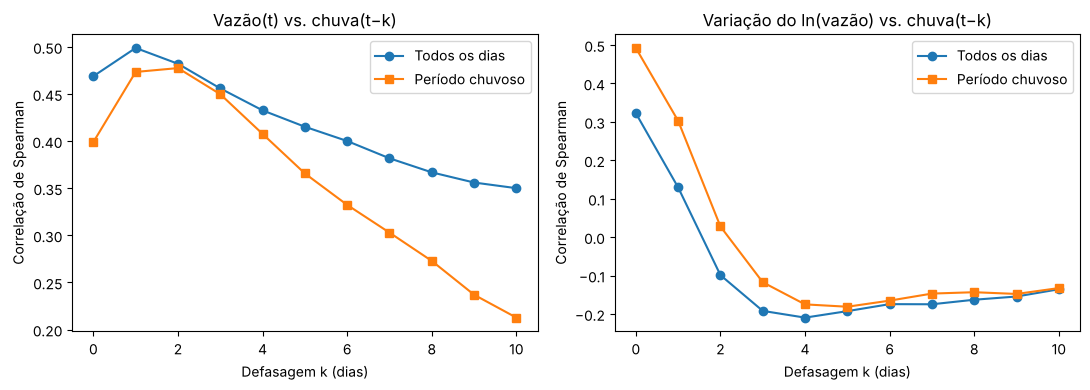

In [8]:
def passo_defasagem(df, chuva_col="rain_mm", mascara_periodo=None, imprimir=True, grafico=True):
    """Correlação defasada e verificação da persistência, no período indicado."""
    vazao, chuva = df["flow_m3s"], df[chuva_col]
    periodo = mascara_periodo if mascara_periodo is not None else pd.Series(True, index=df.index)
    chuvoso = pd.Series(df.index.month.isin(MESES_CHUVOSOS), index=df.index)
    lags = range(0, MAX_LAG + 1)
    dlogq = np.log(vazao.clip(lower=1e-3)).diff()

    tab = pd.DataFrame({
        "vazao_todos": correlacao_defasada(vazao, chuva, lags, periodo),
        "vazao_chuvoso": correlacao_defasada(vazao, chuva, lags, periodo & chuvoso),
        "dlogQ_todos": correlacao_defasada(dlogq, chuva, lags, periodo),
        "dlogQ_chuvoso": correlacao_defasada(dlogq, chuva, lags, periodo & chuvoso),
    })
    tab.index.name = "defasagem_dias"
    melhor = int(tab["vazao_todos"].idxmax())

    if imprimir:
        tab.round(3).to_csv(OUT / "3_4_correlacao_defasada.csv")
        display(tab.round(3))
        print("Melhor defasagem (todos os dias):", melhor, "dia(s)")
        print("Melhor defasagem (período chuvoso):", int(tab["vazao_chuvoso"].idxmax()), "dia(s)")
        print("Melhor defasagem da variação da vazão (todos):", int(tab["dlogQ_todos"].idxmax()), "dia(s)")
    if grafico:
        fig, ax = plt.subplots(1, 2, figsize=(11, 4))
        ax[0].plot(tab.index, tab["vazao_todos"], marker="o", label="Todos os dias")
        ax[0].plot(tab.index, tab["vazao_chuvoso"], marker="s", label="Período chuvoso")
        ax[0].set_title("Vazão(t) vs. chuva(t−k)")
        ax[1].plot(tab.index, tab["dlogQ_todos"], marker="o", label="Todos os dias")
        ax[1].plot(tab.index, tab["dlogQ_chuvoso"], marker="s", label="Período chuvoso")
        ax[1].set_title("Variação do ln(vazão) vs. chuva(t−k)")
        for a in ax:
            a.set_xlabel("Defasagem k (dias)")
            a.set_ylabel("Correlação de Spearman")
            a.legend()
        salvar_fig("3_4_correlacao_defasada.png")
    return melhor, tab


print(f"Período de treino (até {ANO_CORTE}):")
melhor_lag, tab_lag = passo_defasagem(df, mascara_periodo=treino)

In [9]:
def estabilidade_selecao(df, col="rain_mm"):
    """Defasagem e janela ótimas em cada período, para checar se a escolha do treino se mantém."""
    chuvoso = pd.Series(df.index.month.isin(MESES_CHUVOSOS), index=df.index)
    periodos = {"Treino": treino, "Teste": ~treino, "Série completa": pd.Series(True, index=df.index)}
    linhas = []
    for nome, m in periodos.items():
        for sub, mm in [("todos os dias", m), ("período chuvoso", m & chuvoso)]:
            linhas.append({"periodo": nome, "subconjunto": sub,
                           "melhor_defasagem_dias": melhor_defasagem(df, col, mm),
                           "melhor_janela_dias": melhor_janela(df, col, mm)})
    tab = pd.DataFrame(linhas)
    tab.to_csv(OUT / "3_4_estabilidade_selecao.csv", index=False)
    return tab


display(estabilidade_selecao(df))

,periodo,subconjunto,melhor_defasagem_dias,melhor_janela_dias
0,Treino,todos os dias,1,30
1,Treino,período chuvoso,2,7
2,Teste,todos os dias,2,30
3,Teste,período chuvoso,2,30
4,Série completa,todos os dias,1,30
5,Série completa,período chuvoso,2,15


### Análise por eventos

Eventos acima do P95: 58 | com chuva diária >= 20 mm nos 10 dias anteriores: 55


,n_eventos,mediana,q25,q75,minimo,maximo
Todos os eventos,58.0,2.0,1.0,4.0,0.0,10.0
Chuva máxima >= 20 mm,55.0,2.0,1.0,4.0,0.0,10.0


Distribuição da defasagem (nº de eventos por intervalo em dias):


,todos,chuva_relevante
defasagem_dias,,
0,5,5
1,14,12
2,12,12
3,8,8
4,5,5
6,2,2
7,2,2
8,2,2
9,4,3


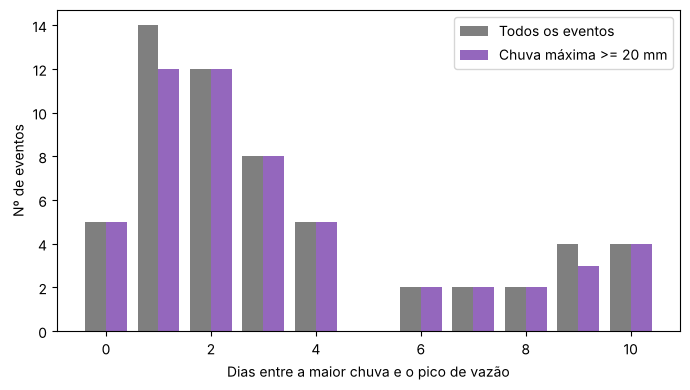

In [10]:
def passo_defasagem_eventos(ev):
    """Dias entre a maior chuva e o pico, em todos os eventos acima do P95."""
    ev = ev.copy()
    ev["chuva_relevante"] = ev["maior_chuva_antes"] >= MIN_CHUVA_EVENTO
    ev.to_csv(OUT / "3_4_defasagem_eventos.csv", index=False)

    def resumo(d):
        return {"n_eventos": len(d), "mediana": d.median(), "q25": d.quantile(0.25),
                "q75": d.quantile(0.75), "minimo": d.min(), "maximo": d.max()}

    todos = ev["defasagem_dias"].dropna()
    relev = ev.loc[ev["chuva_relevante"], "defasagem_dias"].dropna()
    tab = pd.DataFrame({"Todos os eventos": resumo(todos),
                        f"Chuva máxima >= {MIN_CHUVA_EVENTO} mm": resumo(relev)}).T.round(1)
    print(f"Eventos acima do P95: {len(ev)} | com chuva diária >= {MIN_CHUVA_EVENTO} mm nos "
          f"{LOOKBACK} dias anteriores: {int(ev['chuva_relevante'].sum())}")
    display(tab)

    print("Distribuição da defasagem (nº de eventos por intervalo em dias):")
    display(pd.DataFrame({"todos": todos.value_counts().sort_index(),
                          "chuva_relevante": relev.value_counts().sort_index()}).fillna(0).astype(int))

    bins = np.arange(-0.5, LOOKBACK + 1.5, 1)
    plt.figure(figsize=(7, 4))
    plt.hist([todos, relev], bins=bins, label=["Todos os eventos", f"Chuva máxima >= {MIN_CHUVA_EVENTO} mm"],
             color=["tab:gray", "tab:purple"])
    plt.xlabel("Dias entre a maior chuva e o pico de vazão")
    plt.ylabel("Nº de eventos")
    plt.legend()
    salvar_fig("3_4_histograma_defasagem_eventos.png")


passo_defasagem_eventos(eventos["p95"])

## 6. Chuva acumulada e análise de limiar (seção 3.5)

,spearman
janela_dias,
1,0.469
3,0.559
7,0.611
15,0.630
30,0.672


Melhor janela (treino): 30 dias


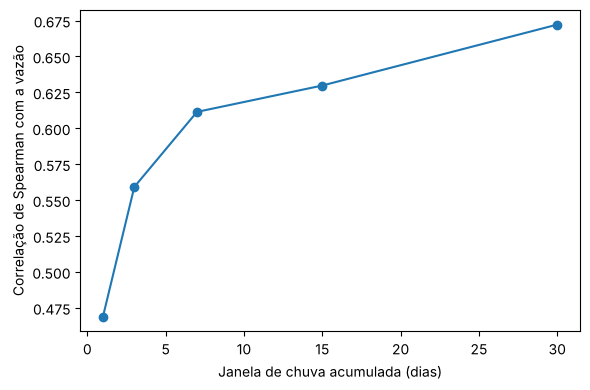

Vazão por decil de chuva acumulada em 30 dias:


,chuva_media,vazao_mediana,vazao_p90,n
faixa,,,,
"(-0.001, 4.3]",0.6,0.8,1.1,2130
"(4.3, 17.98]",10.2,0.8,1.3,1064
"(17.98, 36.1]",27.0,0.9,1.4,1080
"(36.1, 65.9]",50.8,1.1,1.6,1058
"(65.9, 112.62]",88.5,1.2,2.7,1056
"(112.62, 163.9]",136.8,1.2,4.0,1066
"(163.9, 231.6]",195.4,1.9,6.0,1064
"(231.6, 314.64]",273.2,3.2,9.0,1064
"(314.64, 822.0]",422.5,6.7,17.5,1065


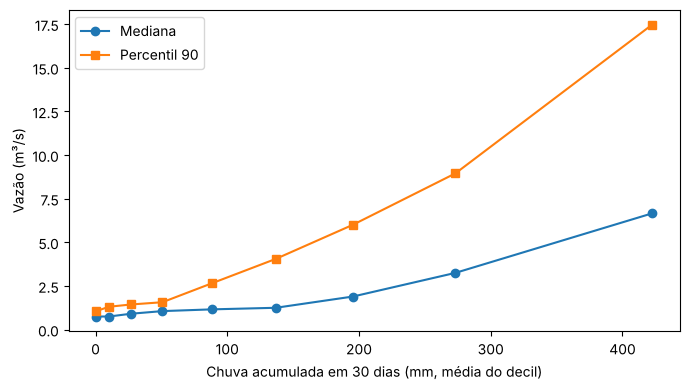

In [ ]:
def passo_janelas(df, mascara_periodo=None):
    tab = correlacao_janelas(df, "rain_mm", mascara_periodo)
    tab.index.name = "janela_dias"
    melhor = int(tab.idxmax())
    tab.round(3).rename("spearman").to_csv(OUT / "3_5_correlacao_janelas.csv")
    display(tab.round(3).rename("spearman").to_frame())
    print("Melhor janela (treino):", melhor, "dias")

    plt.figure(figsize=(6, 4))
    plt.plot(tab.index, tab.values, marker="o")
    plt.xlabel("Janela de chuva acumulada (dias)")
    plt.ylabel("Correlação de Spearman com a vazão")
    salvar_fig("3_5_correlacao_janelas.png")

    acc = chuva_acumulada(df["rain_mm"], melhor).rename("acc")
    d = pd.concat([acc, df["flow_m3s"]], axis=1).dropna()
    d["faixa"] = pd.qcut(d["acc"], 10, duplicates="drop")
    faixas = d.groupby("faixa", observed=True).agg(
        chuva_media=("acc", "mean"), vazao_mediana=("flow_m3s", "median"),
        vazao_p90=("flow_m3s", lambda s: s.quantile(0.90)), n=("flow_m3s", "size"))
    faixas.round(2).to_csv(OUT / "3_5_vazao_por_faixa_de_chuva.csv")
    print(f"Vazão por decil de chuva acumulada em {melhor} dias:")
    display(faixas.round(1))

    plt.figure(figsize=(7, 4))
    plt.plot(faixas["chuva_media"], faixas["vazao_mediana"], marker="o", label="Mediana")
    plt.plot(faixas["chuva_media"], faixas["vazao_p90"], marker="s", label="Percentil 90")
    plt.xlabel(f"Chuva acumulada em {melhor} dias (mm, média do decil)")
    plt.ylabel("Vazão (m³/s)")
    plt.legend()
    salvar_fig("3_5_vazao_por_faixa_de_chuva.png")
    return melhor


melhor_janela_treino = passo_janelas(df, treino)

## 7. Modelo de probabilidade de vazão extrema (seção 3.7)

Regressão logística para a probabilidade de a vazão ultrapassar o percentil 95 do período de treino. Três especificações, cada uma com uma variável explicativa transformada por ln(1 + x) e padronizada:

- (a) chuva do mesmo dia;
- (b) chuva defasada pelo valor estimado no treino (seção 5);
- (c) chuva acumulada na melhor janela do treino (seção 6).

Referências: um modelo apenas com o mês do ano e um modelo com a vazão do dia anterior (limite superior, não comparável aos modelos só com chuva).

Métricas:
- AUC: capacidade de ordenar dias extremos acima dos demais. *Com uma única variável explicativa, a regressão logística é monotônica, então a AUC é igual à do próprio preditor, e transformações como ln(1 + x) ou a padronização não a alteram.* Por isso a AUC sozinha não mostra o que o modelo acrescenta.
- PR-AUC (precisão média): mais informativa com classes raras. A linha de base é a prevalência de dias extremos no teste.
- Escore de Brier: erro quadrático das probabilidades, que mede também a calibração. O escore de habilidade (BSS) compara com prever sempre a frequência do treino (BSS > 0 é melhor que isso).

Os intervalos de confiança de 95% e as diferenças em relação ao modelo (a) vêm de bootstrap em blocos móveis de `BLOCO` dias. Treino até `ANO_CORTE`, teste depois. O limiar de decisão (para precisão, sensibilidade e F1) é escolhido maximizando o F1 no treino.

In [12]:
def montar_features(df, chuva_col, lag, janela):
    r = df[chuva_col]
    meses = pd.get_dummies(df.index.month, prefix="mes", drop_first=True).astype(float)
    meses.index = df.index
    return {
        "a_chuva_do_dia": pd.DataFrame({"x": np.log1p(r)}),
        f"b_chuva_defasada_{lag}d": pd.DataFrame({"x": np.log1p(r.shift(lag))}),
        f"c_chuva_acumulada_{janela}d": pd.DataFrame({"x": np.log1p(chuva_acumulada(r, janela))}),
        "ref_sazonal_(mes)": meses,
        "ref_vazao_de_ontem": pd.DataFrame({"x": np.log(df["flow_m3s"].clip(lower=1e-3).shift(1))}),
    }


def limiar_f1(y, p):
    prec, rec, th = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-12)
    return th[int(np.argmax(f1))]


def metricas(y, p):
    return {"AUC": roc_auc_score(y, p), "PR_AUC": average_precision_score(y, p),
            "Brier": brier_score_loss(y, p)}


def bootstrap_em_blocos(y, probs, n_boot, rng):
    """Bootstrap em blocos móveis (preserva a dependência temporal). Métricas pareadas entre modelos."""
    n = len(y)
    nb = int(np.ceil(n / BLOCO))
    res = {k: [] for k in probs}
    for _ in range(n_boot):
        inicios = rng.integers(0, max(n - BLOCO, 1), size=nb)
        idx = np.concatenate([np.arange(s, min(s + BLOCO, n)) for s in inicios])[:n]
        yy = y[idx]
        if yy.min() == yy.max():
            continue
        for k, p in probs.items():
            res[k].append(metricas(yy, p[idx]))
    return {k: pd.DataFrame(v) for k, v in res.items()}


ORDEM_COLUNAS = ["AUC", "AUC_IC_inf", "AUC_IC_sup", "PR_AUC", "PR_AUC_IC_inf", "PR_AUC_IC_sup",
                 "Brier", "Brier_IC_inf", "Brier_IC_sup", "BSS",
                 "precisao", "sensibilidade", "F1", "limiar_decisao"]


def ajustar_avaliar(feats, y, mascara=None, n_boot=N_BOOT):
    """Ajusta uma regressão logística por especificação, com treino/teste cronológico.
    Retorna (tabela de desempenho, tabela de diferenças vs. modelo a, curvas)."""
    idx = y.dropna().index
    for X in feats.values():
        idx = idx.intersection(X.dropna().index)
    if mascara is not None:
        idx = idx.intersection(mascara[mascara].index)
    tr, te = idx[idx.year <= ANO_CORTE], idx[idx.year > ANO_CORTE]
    ytr, yte = y.loc[tr].values, y.loc[te].values

    p_clim = ytr.mean()                              # referência: frequência do treino
    brier_ref = np.mean((yte - p_clim) ** 2)

    probs, linhas, roc_c, pr_c, auc_bruto = {}, [], {}, {}, {}
    for nome, X in feats.items():
        modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
        modelo.fit(X.loc[tr], ytr)
        p_tr = modelo.predict_proba(X.loc[tr])[:, 1]
        p_te = modelo.predict_proba(X.loc[te])[:, 1]
        lim = limiar_f1(ytr, p_tr)                   # limiar de decisão escolhido só no treino
        prec, rec, f1, _ = precision_recall_fscore_support(
            yte, (p_te >= lim).astype(int), average="binary", zero_division=0)
        m = metricas(yte, p_te)
        linhas.append({"modelo": nome, **m, "BSS": 1 - m["Brier"] / brier_ref,
                       "precisao": prec, "sensibilidade": rec, "F1": f1, "limiar_decisao": lim})
        probs[nome] = p_te
        roc_c[nome] = roc_curve(yte, p_te)[:2]
        pr_c[nome] = precision_recall_curve(yte, p_te)[1::-1]      # (recall, precision)
        if list(X.columns) == ["x"]:
            auc_bruto[nome] = roc_auc_score(yte, X.loc[te, "x"])
    tab = pd.DataFrame(linhas).set_index("modelo")

    delta = None
    if n_boot > 0:
        rng = np.random.default_rng(SEED)
        res = bootstrap_em_blocos(yte, probs, n_boot, rng)
        ref = next(k for k in feats if k.startswith("a_"))
        for k in feats:
            for m in ("AUC", "PR_AUC", "Brier"):
                tab.loc[k, f"{m}_IC_inf"], tab.loc[k, f"{m}_IC_sup"] = np.percentile(res[k][m], [2.5, 97.5])
        linhas_d = []
        for k in feats:
            if k == ref:
                continue
            row = {"modelo": k}
            for m in ("AUC", "PR_AUC", "Brier"):
                dif = res[k][m].values - res[ref][m].values
                lo, hi = np.percentile(dif, [2.5, 97.5])
                row[f"d{m}"] = tab.loc[k, m] - tab.loc[ref, m]
                row[f"d{m}_IC_inf"], row[f"d{m}_IC_sup"] = lo, hi
            linhas_d.append(row)
        delta = pd.DataFrame(linhas_d).set_index("modelo")

    tab = tab[[c for c in ORDEM_COLUNAS if c in tab.columns]]
    tab.attrs.update(n_treino=len(tr), n_teste=len(te), pos_treino=int(ytr.sum()), pos_teste=int(yte.sum()),
                     prev_treino=float(ytr.mean()), prev_teste=float(yte.mean()), auc_bruto=auc_bruto)
    return tab, delta, {"roc": roc_c, "pr": pr_c}

Limiar (P95 do treino): 9.69 m³/s | defasagem (treino): 1 d | janela (treino): 30 d
Treino: 6910 dias (329 extremos, 4.8%) | Teste: 3737 dias (146 extremos, 3.9%)
PR-AUC de um modelo sem informação = prevalência no teste = 0.039

Desempenho no teste (IC 95% por bootstrap em blocos):


,AUC,AUC_IC_inf,AUC_IC_sup,PR_AUC,PR_AUC_IC_inf,PR_AUC_IC_sup,Brier,Brier_IC_inf,Brier_IC_sup,BSS,precisao,sensibilidade,F1,limiar_decisao
modelo,,,,,,,,,,,,,,
a_chuva_do_dia,0.740,0.693,0.785,0.122,0.063,0.196,0.037,0.021,0.054,0.019,0.121,0.322,0.176,0.133
b_chuva_defasada_1d,0.788,0.752,0.827,0.183,0.102,0.257,0.036,0.021,0.053,0.046,0.142,0.438,0.215,0.127
c_chuva_acumulada_30d,0.941,0.908,0.966,0.426,0.246,0.580,0.030,0.017,0.043,0.215,0.306,0.699,0.426,0.189
ref_sazonal_(mes),0.866,0.795,0.925,0.168,0.068,0.300,0.034,0.020,0.050,0.089,0.135,0.596,0.220,0.153
ref_vazao_de_ontem,0.996,0.992,0.998,0.936,0.865,0.969,0.009,0.005,0.013,0.771,0.901,0.808,0.852,0.577


Diferença em relação ao modelo (a) (Brier: valores negativos = melhor):


,dAUC,dAUC_IC_inf,dAUC_IC_sup,dPR_AUC,dPR_AUC_IC_inf,dPR_AUC_IC_sup,dBrier,dBrier_IC_inf,dBrier_IC_sup
modelo,,,,,,,,,
b_chuva_defasada_1d,0.048,0.022,0.082,0.061,0.019,0.101,-0.001,-0.003,0.000
c_chuva_acumulada_30d,0.201,0.147,0.251,0.305,0.149,0.442,-0.007,-0.013,-0.003
ref_sazonal_(mes),0.126,0.036,0.199,0.047,-0.032,0.154,-0.003,-0.006,0.000
ref_vazao_de_ontem,0.256,0.211,0.301,0.814,0.742,0.857,-0.028,-0.043,-0.015


Maior diferença entre a AUC do modelo e a do preditor bruto: 0.00e+00 (zero, como esperado para modelos de uma variável)


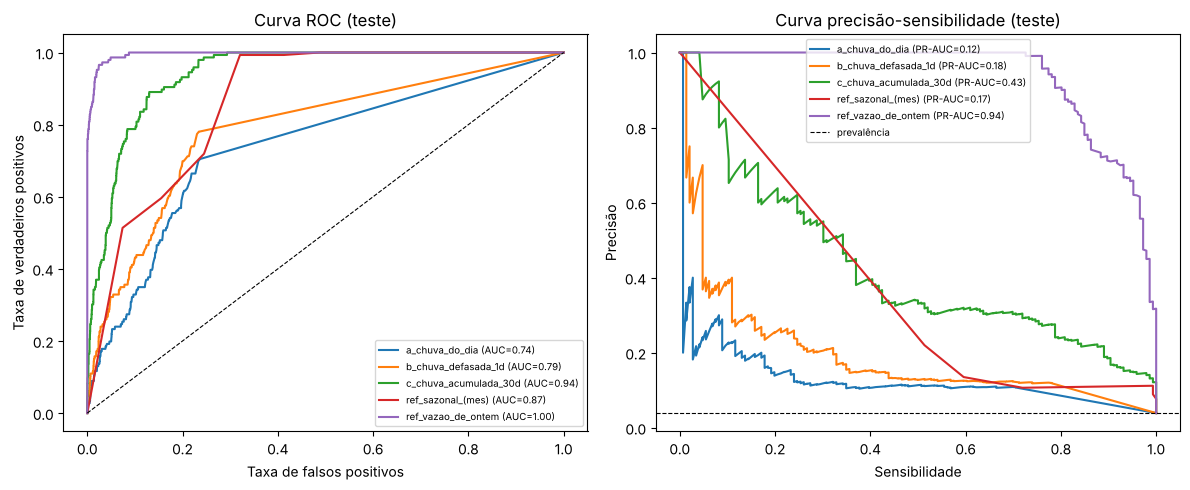

Desempenho no teste por janela de chuva acumulada:


,AUC,PR_AUC,Brier,BSS
janela_dias,,,,
1,0.739,0.119,0.037,0.015
3,0.838,0.257,0.034,0.086
7,0.924,0.433,0.029,0.214
15,0.946,0.466,0.028,0.247
30,0.941,0.426,0.030,0.215


In [ ]:
def passo_modelo(df, melhor_lag, melhor_janela):
    y = (df["flow_m3s"] > LIM95).astype(int)
    feats = montar_features(df, "rain_mm", melhor_lag, melhor_janela)
    tab, delta, curvas = ajustar_avaliar(feats, y)

    a = tab.attrs
    print(f"Limiar (P95 do treino): {LIM95:.2f} m³/s | defasagem (treino): {melhor_lag} d | "
          f"janela (treino): {melhor_janela} d")
    print(f"Treino: {a['n_treino']} dias ({a['pos_treino']} extremos, {a['prev_treino']:.1%}) | "
          f"Teste: {a['n_teste']} dias ({a['pos_teste']} extremos, {a['prev_teste']:.1%})")
    print(f"PR-AUC de um modelo sem informação = prevalência no teste = {a['prev_teste']:.3f}")

    tab.round(3).to_csv(OUT / "3_7_modelos_logisticos.csv")
    delta.round(3).to_csv(OUT / "3_7_diferencas_vs_a.csv")
    print("\nDesempenho no teste (IC 95% por bootstrap em blocos):")
    display(tab.round(3))
    print("Diferença em relação ao modelo (a) (Brier: valores negativos = melhor):")
    display(delta.round(3))

    dif = max(abs(tab.loc[k, "AUC"] - v) for k, v in a["auc_bruto"].items())
    print(f"Maior diferença entre a AUC do modelo e a do preditor bruto: {dif:.2e} "
          "(zero, como esperado para modelos de uma variável)")

    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    for nome, (fpr, tpr) in curvas["roc"].items():
        ax[0].plot(fpr, tpr, label=f"{nome} (AUC={tab.loc[nome, 'AUC']:.2f})")
    ax[0].plot([0, 1], [0, 1], "k--", lw=0.8)
    ax[0].set_xlabel("Taxa de falsos positivos")
    ax[0].set_ylabel("Taxa de verdadeiros positivos")
    ax[0].set_title("Curva ROC (teste)")
    ax[0].legend(fontsize=7)
    for nome, (rec, prec) in curvas["pr"].items():
        ax[1].plot(rec, prec, label=f"{nome} (PR-AUC={tab.loc[nome, 'PR_AUC']:.2f})")
    ax[1].axhline(a["prev_teste"], color="k", ls="--", lw=0.8, label="prevalência")
    ax[1].set_xlabel("Sensibilidade")
    ax[1].set_ylabel("Precisão")
    ax[1].set_title("Curva precisão-sensibilidade (teste)")
    ax[1].legend(fontsize=7)
    salvar_fig("3_7_curvas_roc_pr.png")

    # desempenho do modelo com cada janela de chuva acumulada
    linhas = {}
    for n in JANELAS:
        X = {f"janela_{n}d": pd.DataFrame({"x": np.log1p(chuva_acumulada(df["rain_mm"], n))})}
        t, _, _ = ajustar_avaliar(X, y, n_boot=0)
        linhas[n] = t.iloc[0][["AUC", "PR_AUC", "Brier", "BSS"]]
    por_janela = pd.DataFrame(linhas).T
    por_janela.index.name = "janela_dias"
    por_janela.round(3).to_csv(OUT / "3_7_desempenho_por_janela.csv")
    print("Desempenho no teste por janela de chuva acumulada:")
    display(por_janela.round(3))
    return tab, delta


tab_modelos, delta_modelos = passo_modelo(df, melhor_lag, melhor_janela_treino)

## 8. Verificação de robustez (seção 3.8)
Os resultados principais (defasagem, janela e desempenho dos modelos a, b e c) são recalculados:

1. com a chuva do INMET no lugar da chuva da ANA;
2. apenas com o período chuvoso (novembro a março);
3. com o percentil 99 (do treino) como limiar.

Em cada, a defasagem e a janela são reestimadas somente com o treino e os modelos são reajustados. Os valores abaixo são estimativas pontuais (sem intervalos de confiança).

In [14]:
def passo_robustez(df):
    chuvoso = pd.Series(df.index.month.isin(MESES_CHUVOSOS), index=df.index)
    variantes = [
        ("Base (ANA, P95, todos os meses)", "rain_mm", PCT_PRINCIPAL, None),
        ("Chuva do INMET", "rain_inmet_mm", PCT_PRINCIPAL, None),
        ("Apenas período chuvoso", "rain_mm", PCT_PRINCIPAL, chuvoso),
        ("Limiar P99", "rain_mm", PCT_RESTRITIVO, None),
    ]
    linhas = []
    for nome, col, pct, mascara in variantes:
        sel = treino if mascara is None else (treino & mascara)    # seleção só com o treino
        lag = melhor_defasagem(df, col, sel)
        janela = melhor_janela(df, col, sel)
        limiar = df.loc[treino, "flow_m3s"].quantile(pct)
        y = (df["flow_m3s"] > limiar).astype(int)
        feats = montar_features(df, col, lag, janela)
        feats = {k: v for k, v in feats.items() if not k.startswith("ref_")}
        tab, _, _ = ajustar_avaliar(feats, y, mascara, n_boot=0)
        for modelo, r in tab.iterrows():
            linhas.append({"variante": nome, "modelo": modelo, "defasagem_dias": lag, "janela_dias": janela,
                           "limiar_m3s": round(limiar, 1), "AUC": r["AUC"], "PR_AUC": r["PR_AUC"],
                           "Brier": r["Brier"], "BSS": r["BSS"],
                           "extremos_no_teste": tab.attrs["pos_teste"]})
    res = pd.DataFrame(linhas).round(3)
    res.to_csv(OUT / "3_8_robustez.csv", index=False)
    display(res)
    return res


robustez = passo_robustez(df)

,variante,modelo,defasagem_dias,janela_dias,limiar_m3s,AUC,PR_AUC,Brier,BSS,extremos_no_teste
0,"Base (ANA, P95, todos os meses)",a_chuva_do_dia,1,30,9.7,0.740,0.122,0.037,0.019,146
1,"Base (ANA, P95, todos os meses)",b_chuva_defasada_1d,1,30,9.7,0.788,0.183,0.036,0.046,146
2,"Base (ANA, P95, todos os meses)",c_chuva_acumulada_30d,1,30,9.7,0.941,0.426,0.030,0.215,146
3,Chuva do INMET,a_chuva_do_dia,1,30,9.7,0.720,0.119,0.036,0.010,138
4,Chuva do INMET,b_chuva_defasada_1d,1,30,9.7,0.779,0.178,0.034,0.049,138
5,Chuva do INMET,c_chuva_acumulada_30d,1,30,9.7,0.946,0.351,0.029,0.193,138
6,Apenas período chuvoso,a_chuva_do_dia,2,7,9.7,0.639,0.156,0.084,0.004,146
7,Apenas período chuvoso,b_chuva_defasada_2d,2,7,9.7,0.739,0.246,0.079,0.054,146
8,Apenas período chuvoso,c_chuva_acumulada_7d,2,7,9.7,0.837,0.444,0.070,0.171,146
9,Limiar P99,a_chuva_do_dia,1,30,18.9,0.801,0.083,0.011,0.025,43
